In [1]:
# Instalasi Annoy dulu untuk langkah awal.
!pip install annoy

     ---------------------------------------- 0.0/647.5 kB ? eta -:--:--
     ------------------------------ ------- 524.3/647.5 kB 3.1 MB/s eta 0:00:01
     ---------------------------------------- 647.5/647.5 kB 3.0 MB/s  0:00:00
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Installing backend dependencies: started
  Installing backend dependencies: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for annoy: filename=annoy-1.17.3-cp314-cp314-win_amd64.whl size=55852 sha256=f29ea34768dc653bcdd1fec6329c516be3f91221b4fc9927dc39194767583ab9
  Stored in directory: c:\users\andre\appdata\local\pip\cache\wheels\b5\50\ac\30128de49aebecd15f90a8142d542bb176b6941fcfde95f331
Successfully built annoy


Exact NN index: [219 898 593]
Exact NN jarak: [0.         1.36915938 2.27931544]
Waktu Exact: 0.2615 ms

Annoy NN index: [219, 898, 593]
Annoy NN jarak: [np.float64(0.0), np.float64(1.369159376273702), np.float64(2.2793154441691197)]
Waktu Annoy: 0.1156 ms


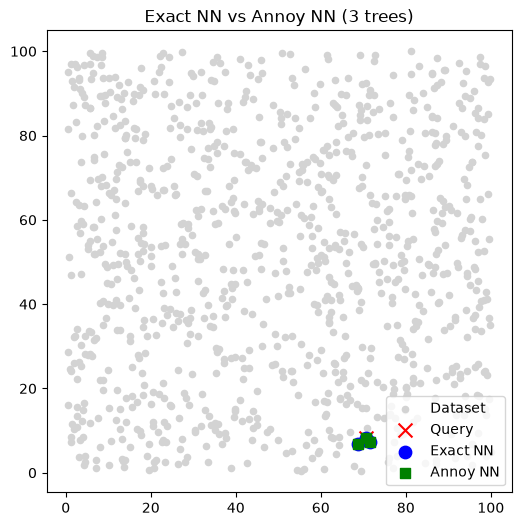

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import time

from annoy import AnnoyIndex

# 1. Dataset 2D
np.random.seed(42)
n_points = 1000
X = np.random.rand(n_points, 2) * 100  # titik random dalam ruang 100x100

# Query point (ambil salah satu titik random)
query = X[np.random.randint(0, n_points)]

# 2. Exact NN (brute force)
start = time.time()
distances = np.linalg.norm(X - query, axis=1)
idx_exact = np.argsort(distances)[:3]  # ambil 3 terdekat
time_exact = time.time() - start

print("Exact NN index:", idx_exact)
print("Exact NN jarak:", distances[idx_exact])
print("Waktu Exact:", round(time_exact*1000, 4), "ms")

# 3. Annoy NN (3 tree)
f = 2  # dimensi
t = AnnoyIndex(f, 'euclidean')
for i, vec in enumerate(X):
    t.add_item(i, vec)

t.build(3)  # 3 trees

start = time.time()
idx_ann = t.get_nns_by_vector(query, 3)  # cari 3 NN
time_ann = time.time() - start

print("\nAnnoy NN index:", idx_ann)
print("Annoy NN jarak:", [np.linalg.norm(X[i]-query) for i in idx_ann])
print("Waktu Annoy:", round(time_ann*1000, 4), "ms")

# 4. Visualisasi hasil
plt.figure(figsize=(6,6))
plt.scatter(X[:,0], X[:,1], c="lightgray", s=20, label="Dataset")
plt.scatter(query[0], query[1], c="red", marker="x", s=100, label="Query")

# Exact NN ditandai biru
plt.scatter(X[idx_exact,0], X[idx_exact,1], c="blue", s=80, label="Exact NN")

# Annoy NN ditandai hijau
plt.scatter(X[idx_ann,0], X[idx_ann,1], c="green", s=50, marker="s", label="Annoy NN")

plt.legend()
plt.title("Exact NN vs Annoy NN (3 trees)")
plt.show()

In [ ]:
import time
import numpy as np
from annoy import AnnoyIndex

# fungsi bantuan untuk pengujian otomatis tiap parameter
def uji_annoy(metric='euclidean', n_trees=3, n_points=1000):
    np.random.seed(42)
    
    # membuat titik koordinat acak
    x = np.random.rand(n_points, 2) * 100
    query = x[np.random.randint(0, n_points)]

    # pencarian eksak manual brute force
    t_mulai = time.time()
    if metric == 'euclidean':
        jarak_exact = np.linalg.norm(x - query, axis=1)
    else:
        # normalisasi vektor untuk perhitungan jarak sudut atau angular
        norm_x = x / np.linalg.norm(x, axis=1, keepdims=True)
        norm_q = query / np.linalg.norm(query)
        jarak_exact = np.linalg.norm(norm_x - norm_q, axis=1)
        
    idx_exact = np.argsort(jarak_exact)[:3]
    t_exact = (time.time() - t_mulai) * 1000

    # pencarian perkiraan menggunakan pustaka annoy
    t_index = AnnoyIndex(2, metric)
    for i, vec in enumerate(x):
        t_index.add_item(i, vec)
    t_index.build(n_trees)

    t_mulai_ann = time.time()
    idx_ann = t_index.get_nns_by_vector(query, 3)
    t_ann = (time.time() - t_mulai_ann) * 1000

    print(f"[{metric.upper()} | Trees: {n_trees} | Data: {n_points}]")
    print(f"Exact : {list(idx_exact)} ({t_exact:.4f} ms)")
    print(f"Annoy : {idx_ann} ({t_ann:.4f} ms)")
    print("-" * 50)

# menjalankan variasi sesuai tabel modul
uji_annoy('euclidean', 3, 1000)
uji_annoy('euclidean', 8, 1000)
uji_annoy('euclidean', 3, 100000)
uji_annoy('angular', 3, 1000)
uji_annoy('angular', 8, 1000)
uji_annoy('angular', 3, 100000)

In [11]:
import time
import numpy as np
from sklearn.metrics.pairwise import euclidean_distances
from annoy import AnnoyIndex

# parameter dataset audio spotify
n_tracks = 1000000
n_features = 20
n_trees = 8

np.random.seed(42)

# membuat fitur audio acak seperti tempo dan energi
x = np.random.rand(n_tracks, n_features).astype(np.float32)
query = np.random.rand(1, n_features).astype(np.float32)

for metric in ['euclidean', 'angular']:
    # menghitung jarak eksak brute force
    t_mulai = time.time()
    if metric == 'euclidean':
        jarak_semua = euclidean_distances(query, x)[0]
    else:
        norm_x = x / np.linalg.norm(x, axis=1, keepdims=True)
        norm_q = query / np.linalg.norm(query)
        jarak_semua = np.linalg.norm(norm_x - norm_q, axis=1)
        
    exact_idx = list(np.argsort(jarak_semua)[:5])
    exact_time = time.time() - t_mulai

    # membangun struktur pohon pencarian annoy
    annoy_index = AnnoyIndex(n_features, metric)
    for i in range(n_tracks):
        annoy_index.add_item(i, x[i])
    annoy_index.build(n_trees)

    # mengukur kecepatan inferensi pencarian rekomendasi lagu
    t_mulai_ann = time.time()
    annoy_idx = annoy_index.get_nns_by_vector(query[0], 5)
    annoy_time = time.time() - t_mulai_ann

    print(f"Metric: {metric.upper()}")
    print("Exact result :", exact_idx, f"| Waktu: {exact_time:.6f} detik")
    print("Annoy result :", annoy_idx, f"| Waktu: {annoy_time:.6f} detik")
    print("=" * 60)

Metric: EUCLIDEAN
Exact result : [np.int64(229350), np.int64(553886), np.int64(763448), np.int64(256344), np.int64(308000)] | Waktu: 0.078264 detik
Annoy result : [93303, 964141, 307048, 516420, 905498] | Waktu: 0.000064 detik
Metric: ANGULAR
Exact result : [np.int64(308000), np.int64(376840), np.int64(229350), np.int64(763448), np.int64(553886)] | Waktu: 0.210939 detik
Annoy result : [387143, 308393, 64908, 292122, 634408] | Waktu: 0.000071 detik
